In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!pip -q install -U ultralytics segmentation_models_pytorch kaggle
import ultralytics
print("ultralytics", ultralytics.__version__)

Mounted at /content/drive
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
ultralytics 8.4.192


In [ ]:
#YOLO11 vs U-Net on Bijie Dataset

import os, glob, re, json, random, time, shutil
import numpy as np, pandas as pd, cv2
from PIL import Image
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F, torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import segmentation_models_pytorch as smp
from tqdm.auto import tqdm

OUT  = '/content/drive/MyDrive/TerraSeg/phase8'
ROOT = '/content/yolo_bijie'
os.makedirs(f'{OUT}/runs', exist_ok=True)

IMG = 256                 # same size as Phase 1
SPLIT_SEED = 42
SEEDS = [42,123,777]             # later: [42, 123, 777]
FORCE = False
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
print("Device:", device)

# ---- Kaggle credentials: Colab secrets first, otherwise upload kaggle.json ----
try:
    from google.colab import userdata
    os.environ['KAGGLE_USERNAME'] = userdata.get('KAGGLE_USERNAME')
    os.environ['KAGGLE_KEY'] = userdata.get('KAGGLE_KEY')
    print("Kaggle credentials loaded from Colab secrets")
except Exception:
    if not os.path.exists('/root/.kaggle/kaggle.json'):
        from google.colab import files
        print("No secrets found. Please upload kaggle.json now:")
        up = files.upload()
        os.makedirs('/root/.kaggle', exist_ok=True)
        shutil.move(list(up.keys())[0], '/root/.kaggle/kaggle.json')
        os.chmod('/root/.kaggle/kaggle.json', 0o600)

Device: cuda
No secrets found. Please upload kaggle.json now:


Saving kaggle.json to kaggle.json


In [ ]:
!kaggle datasets download -d ksncik/bijie-landslide-dataset
!mkdir -p /content/bijie_data
!unzip -q -o bijie-landslide-dataset.zip -d /content/bijie_data

BIJIE_IMG_DIR, BIJIE_MASK_DIR = None, None
print("Folders containing PNG files:")
for root, dirs, files in os.walk('/content/bijie_data'):
    pngs = [f for f in files if f.lower().endswith('.png')]
    if pngs:
        print(f"  {len(pngs):5d}  {root}")
    name = os.path.basename(root).lower()
    if 'image' in name and pngs: BIJIE_IMG_DIR = root
    elif 'mask' in name and pngs: BIJIE_MASK_DIR = root
print("\nUsing images:", BIJIE_IMG_DIR)
print("Using masks :", BIJIE_MASK_DIR)
assert BIJIE_IMG_DIR and BIJIE_MASK_DIR, "could not find image/mask folders - look at the list above"

img_names  = sorted(f for f in os.listdir(BIJIE_IMG_DIR) if f.lower().endswith('.png'))
mask_names = sorted(f for f in os.listdir(BIJIE_MASK_DIR) if f.lower().endswith('.png'))
assert len(img_names) == len(mask_names), f"{len(img_names)} images but {len(mask_names)} masks"
bad = sum(os.path.splitext(a)[0] != os.path.splitext(b)[0] for a, b in zip(img_names, mask_names))
print(f"pairs: {len(img_names)} | name mismatches after sorting: {bad}")
sizes = [Image.open(os.path.join(BIJIE_IMG_DIR, n)).size for n in img_names[:30]]
print("original image sizes (first 30):", sorted(set(sizes))[:6])

Dataset URL: https://www.kaggle.com/datasets/ksncik/bijie-landslide-dataset
License(s): unknown
100% 502M/502M [00:14<00:00, 36.9MB/s]

Folders containing PNG files:
   2003  /content/bijie_data/Bijie-landslide-dataset/non-landslide/dem
   2003  /content/bijie_data/Bijie-landslide-dataset/non-landslide/image
    770  /content/bijie_data/Bijie-landslide-dataset/landslide/dem
    770  /content/bijie_data/Bijie-landslide-dataset/landslide/mask
    770  /content/bijie_data/Bijie-landslide-dataset/landslide/image

Using images: /content/bijie_data/Bijie-landslide-dataset/landslide/image
Using masks : /content/bijie_data/Bijie-landslide-dataset/landslide/mask
pairs: 770 | name mismatches after sorting: 0
original image sizes (first 30): [(61, 61), (96, 110), (103, 119), (109, 113), (120, 124), (120, 132)]


In [ ]:
n = len(img_names)
perm = np.random.RandomState(SPLIT_SEED).permutation(n)
n_tr, n_va = int(0.70 * n), int(0.15 * n)
SPLITS = {'train': perm[:n_tr], 'val': perm[n_tr:n_tr + n_va], 'test': perm[n_tr + n_va:]}
json.dump({k: v.tolist() for k, v in SPLITS.items()}, open(f'{OUT}/split.json', 'w'))
print({k: len(v) for k, v in SPLITS.items()})

{'train': 539, 'val': 115, 'test': 116}


In [ ]:
MIN_AREA = 30.0

def mask_to_yolo_lines(mask, min_area=MIN_AREA):
    h, w = mask.shape
    cnts, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    lines = []
    for c in cnts:
        if len(c) < 3 or cv2.contourArea(c) < min_area:
            continue
        pts = c.reshape(-1, 2).astype(np.float64)
        pts[:, 0] /= w; pts[:, 1] /= h
        lines.append('0 ' + ' '.join(f'{v:.5f}' for v in pts.ravel()))
    return lines

shutil.rmtree(ROOT, ignore_errors=True)
for s in SPLITS:
    for sub in ('images', 'labels', 'gt'):
        os.makedirs(f'{ROOT}/{sub}/{s}', exist_ok=True)

inst_counts, inst_areas, landslide_frac = [], [], []
for s, idxs in SPLITS.items():
    for i in tqdm(idxs, desc=s):
        im = Image.open(os.path.join(BIJIE_IMG_DIR, img_names[i])).convert('RGB').resize((IMG, IMG), Image.BILINEAR)
        mk = Image.open(os.path.join(BIJIE_MASK_DIR, mask_names[i])).convert('L').resize((IMG, IMG), Image.NEAREST)
        m = (np.array(mk) > 127).astype(np.uint8)
        name = f'b{int(i):04d}'
        im.save(f'{ROOT}/images/{s}/{name}.png')                     # PIL keeps RGB order; Ultralytics handles the rest
        cv2.imwrite(f'{ROOT}/gt/{s}/{name}.png', m * 255)
        lines = mask_to_yolo_lines(m)
        open(f'{ROOT}/labels/{s}/{name}.txt', 'w').write('\n'.join(lines))
        inst_counts.append(len(lines)); landslide_frac.append(m.mean())
        for c in cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)[0]:
            inst_areas.append(cv2.contourArea(c))

open(f'{ROOT}/data.yaml', 'w').write(
    f"path: {ROOT}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n  0: landslide\n")
print(f"images: {len(inst_counts)} | objects: {sum(inst_counts)} | images with no object: {sum(c == 0 for c in inst_counts)}")
print(f"objects per image: mean {np.mean(inst_counts):.2f}, max {max(inst_counts)}")
print(f"landslide share of pixels: mean {np.mean(landslide_frac)*100:.1f}% | median {np.median(landslide_frac)*100:.1f}%")
print(f"object contour area (px^2): median {np.median(inst_areas):.0f}, 10th pct {np.percentile(inst_areas, 10):.0f}, 90th pct {np.percentile(inst_areas, 90):.0f}")

train:   0%|          | 0/539 [00:00<?, ?it/s]

val:   0%|          | 0/115 [00:00<?, ?it/s]

test:   0%|          | 0/116 [00:00<?, ?it/s]

images: 770 | objects: 770 | images with no object: 0
objects per image: mean 1.00, max 1
landslide share of pixels: mean 10.1% | median 8.0%
object contour area (px^2): median 5056, 10th pct 1558, 90th pct 13483


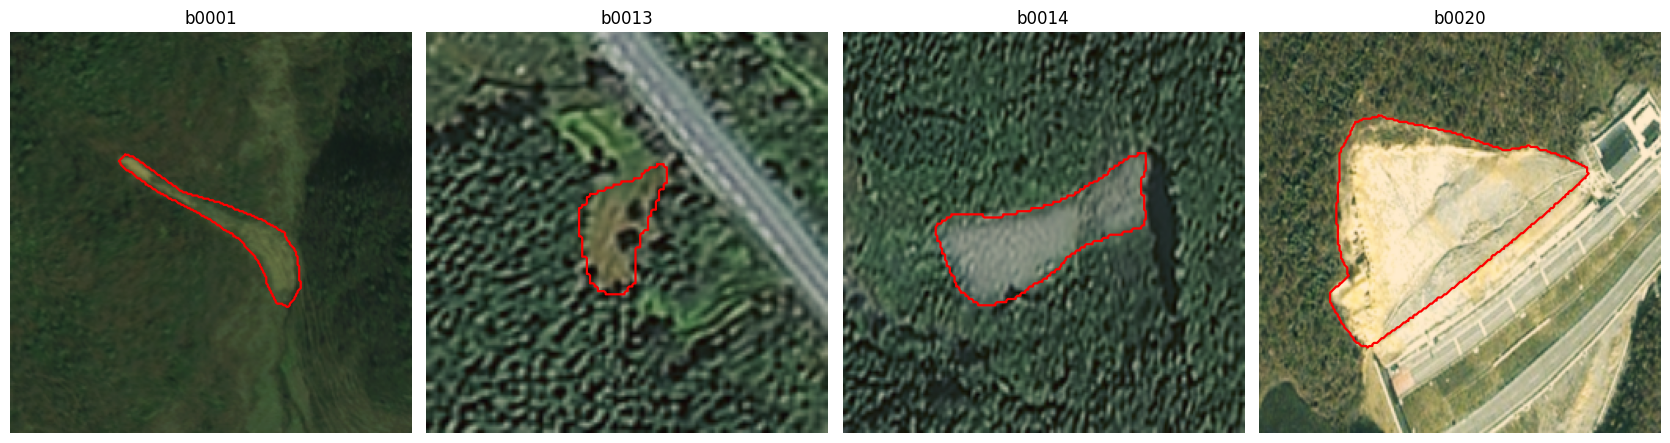

In [ ]:
test_names = sorted(os.path.basename(p)[:-4] for p in glob.glob(f'{ROOT}/images/test/*.png'))
pick = [n for n in test_names if open(f'{ROOT}/labels/test/{n}.txt').read().strip()][:4]
fig, ax = plt.subplots(1, len(pick), figsize=(4.2 * len(pick), 4.4))
for a, n in zip(np.atleast_1d(ax), pick):
    a.imshow(np.array(Image.open(f'{ROOT}/images/test/{n}.png')))
    for line in open(f'{ROOT}/labels/test/{n}.txt').read().strip().split('\n'):
        p = np.array(line.split()[1:], float).reshape(-1, 2) * IMG
        a.plot(np.r_[p[:, 0], p[0, 0]], np.r_[p[:, 1], p[0, 1]], color='red', linewidth=1.6)
    a.set_title(n); a.axis('off')
plt.tight_layout(); plt.show()

In [ ]:
from ultralytics import YOLO

def train_yolo(seed, epochs=150, name=None):
    run = name or f'yolo_s{seed}'
    run_dir = f'{OUT}/runs/{run}'
    best, last = f'{run_dir}/weights/best.pt', f'{run_dir}/weights/last.pt'
    if epochs >= 50 and not FORCE:
        if os.path.exists(best):
            print(f"[{run}] best.pt exists - skipping"); return best
        if os.path.exists(last):
            print(f"[{run}] resuming from last.pt"); YOLO(last).train(resume=True); return best
    YOLO('yolo11s-seg.pt').train(
        data=f'{ROOT}/data.yaml', epochs=epochs, imgsz=IMG, batch=16, seed=seed,
        optimizer='AdamW', lr0=1e-3, weight_decay=1e-4, cos_lr=True, patience=30,
        mosaic=1.0, mixup=0.1, fliplr=0.5, flipud=0.5, close_mosaic=10,
        project=f'{OUT}/runs', name=run, exist_ok=True, workers=2, cache='ram', plots=True)
    return best

train_yolo(seed=0, epochs=3, name='yolo_quicktest')
print("quick test finished -> run the full training next")

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=ram, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/yolo_bijie/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.5, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=256, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolo11s-seg.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolo_quicktest, nbs=64, nms=None, opset=None, optimize=False

In [ ]:
for seed in SEEDS:
    train_yolo(seed, epochs=150)
print("YOLO training finished")

[yolo_s42] best.pt exists - skipping
[yolo_s123] best.pt exists - skipping
[yolo_s777] best.pt exists - skipping
YOLO training finished


In [ ]:
class BijieDS(Dataset):
    def __init__(self, split, aug=False):
        self.names = sorted(os.path.basename(p)[:-4] for p in glob.glob(f'{ROOT}/images/{split}/*.png'))
        self.split, self.aug = split, aug
    def __len__(self): return len(self.names)
    def __getitem__(self, i):
        n = self.names[i]
        x = torch.from_numpy(np.array(Image.open(f'{ROOT}/images/{self.split}/{n}.png').convert('RGB')).astype(np.float32) / 255.0).permute(2, 0, 1)
        y = torch.from_numpy((cv2.imread(f'{ROOT}/gt/{self.split}/{n}.png', 0) > 127).astype(np.float32)).unsqueeze(0)
        if self.aug:
            if random.random() > 0.5: x, y = x.flip(-1), y.flip(-1)
            if random.random() > 0.5: x, y = x.flip(-2), y.flip(-2)
        return (x - torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)) / torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1), y

def dl(split, aug=False, shuffle=False, bs=8, seed=0):
    g = torch.Generator().manual_seed(seed)
    return DataLoader(BijieDS(split, aug), batch_size=bs, shuffle=shuffle, generator=g if shuffle else None, num_workers=2, pin_memory=True)

class BCEDiceLoss(nn.Module):
    def forward(self, logits, t):
        p, tf = torch.sigmoid(logits).view(-1), t.view(-1)
        dice = 1 - (2 * (p * tf).sum() + 1e-6) / (p.sum() + tf.sum() + 1e-6)
        return F.binary_cross_entropy_with_logits(logits, t) + dice

@torch.no_grad()
def collect_probs(model, ldr):
    model.eval(); P, T = [], []
    for x, y in ldr:
        P.append(torch.sigmoid(model(x.to(device)))[:, 0].cpu().numpy().astype(np.float16)); T.append(y[:, 0].numpy().astype(np.uint8))
    return np.concatenate(P), np.concatenate(T)

def pix_metrics(P, T, thr=0.5):
    p, t = P.astype(np.float32) > thr, T == 1
    tp, fp, fn = float((p & t).sum()), float((p & ~t).sum()), float((~p & t).sum()); e = 1e-9
    pr, rc = tp / (tp + fp + e), tp / (tp + fn + e)
    return {'IoU': tp / (tp + fp + fn + e), 'F1': 2 * pr * rc / (pr + rc + e), 'Precision': pr, 'Recall': rc}

def train_unet(seed, epochs=60, patience=10, lr=5e-4):
    ck = f'{OUT}/runs/unet_s{seed}.pth'
    model = smp.Unet('resnet34', encoder_weights='imagenet', in_channels=3, classes=1).to(device)
    if os.path.exists(ck) and not FORCE:
        model.load_state_dict(torch.load(ck, map_location=device)); print(f"[unet_s{seed}] loaded saved weights"); return model
    set_seed(seed)
    tr, va = dl('train', True, True, 8, seed), dl('val')
    crit, opt = BCEDiceLoss(), optim.Adam(model.parameters(), lr=lr)
    best, bad, t0 = -1.0, 0, time.time()
    for ep in range(epochs):
        model.train(); run = 0.0
        for x, y in tr:
            x, y = x.to(device), y.to(device)
            opt.zero_grad(); loss = crit(model(x), y); loss.backward(); opt.step(); run += loss.item()
        Pv, Tv = collect_probs(model, va); v = pix_metrics(Pv, Tv)
        print(f"[unet/{seed}] ep {ep+1:02d} train {run/len(tr):.4f} | val IoU {v['IoU']:.4f} ({time.time()-t0:.0f}s)")
        if v['IoU'] > best: best, bad = v['IoU'], 0; torch.save(model.state_dict(), ck)
        else:
            bad += 1
            if bad >= patience: print("early stopping"); break
    model.load_state_dict(torch.load(ck, map_location=device))
    return model

unets = {s: train_unet(s) for s in SEEDS}

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

[unet_s42] loaded saved weights
[unet_s123] loaded saved weights
[unet_s777] loaded saved weights


In [ ]:
from scipy.ndimage import binary_erosion, distance_transform_edt

def boundary(m): return m & ~binary_erosion(m, border_value=0)

def boundary_f1(pred, gt, tol=2):
    bp, bg = boundary(pred), boundary(gt)
    if bg.sum() == 0 and bp.sum() == 0: return None
    if bg.sum() == 0 or bp.sum() == 0: return 0.0
    dg, dp = distance_transform_edt(~bg), distance_transform_edt(~bp)
    p, r = (dg[bp] <= tol).mean(), (dp[bg] <= tol).mean()
    return 0.0 if p + r == 0 else float(2 * p * r / (p + r))

def pixel_metrics_masks(preds, gts):
    tp = fp = fn = 0.0; bfs = []
    for p, g in zip(preds, gts):
        tp += (p & g).sum(); fp += (p & ~g).sum(); fn += (~p & g).sum()
        if g.any():
            b = boundary_f1(p, g)
            if b is not None: bfs.append(b)
    e = 1e-9; P, R = tp / (tp + fp + e), tp / (tp + fn + e)
    return {'IoU': tp / (tp + fp + fn + e), 'F1': 2 * P * R / (P + R + e), 'Precision': P, 'Recall': R,
            'Boundary F1': float(np.mean(bfs)) if bfs else 0.0}

def load_gts(split, names):
    return [cv2.imread(f'{ROOT}/gt/{split}/{n}.png', 0) > 127 for n in names]

def predict_instances(model, split, conf_min=0.05):
    files = sorted(glob.glob(f'{ROOT}/images/{split}/*.png'))
    names = [os.path.basename(f)[:-4] for f in files]
    out = []
    for r in model.predict(source=files, imgsz=IMG, conf=conf_min, iou=0.7, max_det=50, stream=True, verbose=False, batch=16):
        polys, scores, boxes = [], [], []
        if r.masks is not None and len(r.masks.xy) > 0:
            for poly, sc, bx in zip(r.masks.xy, r.boxes.conf.cpu().numpy(), r.boxes.xyxy.cpu().numpy()):
                if len(poly) >= 3: polys.append(poly); scores.append(float(sc)); boxes.append(bx)
        out.append({'polys': polys, 'scores': scores, 'boxes': boxes})
    return names, out

def render(cache, thr, size=IMG):
    maps = []
    for item in cache:
        m = np.zeros((size, size), np.uint8)
        for poly, sc in zip(item['polys'], item['scores']):
            if sc >= thr: cv2.fillPoly(m, [np.round(poly).astype(np.int32)], 1)
        maps.append(m.astype(bool))
    return maps

_m = np.zeros((IMG, IMG), np.uint8); _m[40:120, 60:150] = 1
_poly = np.array(mask_to_yolo_lines(_m)[0].split()[1:], float).reshape(-1, 2) * IMG
_back = render([{'polys': [_poly], 'scores': [0.9]}], 0.5)[0]
print("self-test: polygon round-trip IoU =", round(float((_back & (_m == 1)).sum() / (_back | (_m == 1)).sum()), 3), "(expect about 1.0)")

self-test: polygon round-trip IoU = 1.0 (expect about 1.0)


In [ ]:
@torch.no_grad()
def unet_fps(model, n=100):
    x = torch.randn(1, 3, IMG, IMG, device=device); model.eval()
    for _ in range(10): model(x)
    torch.cuda.synchronize(); t0 = time.time()
    for _ in range(n): model(x)
    torch.cuda.synchronize(); return n / (time.time() - t0)

rows = []
for seed in SEEDS:
    # ---------- YOLO ----------
    yolo = YOLO(f'{OUT}/runs/yolo_s{seed}/weights/best.pt')
    m = yolo.val(data=f'{ROOT}/data.yaml', split='test', imgsz=IMG, batch=16, verbose=False, plots=False,
                 project=f'{OUT}/runs', name=f'yolo_s{seed}_test', exist_ok=True)
    sp = m.speed; ms = sp['preprocess'] + sp['inference'] + sp['postprocess']
    names_v, cache_v = predict_instances(yolo, 'val'); gts_v = load_gts('val', names_v)
    thrs = np.round(np.arange(0.05, 0.80, 0.05), 2)
    best_conf = float(thrs[int(np.argmax([pixel_metrics_masks(render(cache_v, t), gts_v)['IoU'] for t in thrs]))])
    names_t, cache_t = predict_instances(yolo, 'test'); gts_t = load_gts('test', names_t)
    pm = pixel_metrics_masks(render(cache_t, best_conf), gts_t)
    rows.append({'model': 'YOLO11-seg (RGB)', 'seed': seed, 'threshold': best_conf, **{k: round(v, 4) for k, v in pm.items()},
                 'mask mAP50': round(float(m.seg.map50), 4), 'mask mAP50-95': round(float(m.seg.map), 4),
                 'box mAP50': round(float(m.box.map50), 4), 'FPS': round(1000 / ms, 1)})
    yolo_cache = (names_t, cache_t, best_conf)

    # ---------- U-Net ----------
    net = unets[seed]
    Pv, Tv = collect_probs(net, dl('val')); Pt, Tt = collect_probs(net, dl('test'))
    ut = np.round(np.arange(0.10, 0.91, 0.05), 2)
    best_t = float(ut[int(np.argmax([pix_metrics(Pv, Tv, t)['IoU'] for t in ut]))])
    pmu = pixel_metrics_masks([(p.astype(np.float32) > best_t) for p in Pt], [t == 1 for t in Tt])
    rows.append({'model': 'U-Net ResNet34 (RGB)', 'seed': seed, 'threshold': best_t, **{k: round(v, 4) for k, v in pmu.items()},
                 'mask mAP50': None, 'mask mAP50-95': None, 'box mAP50': None, 'FPS': round(unet_fps(net), 1)})
    unet_probs = (Pt, Tt, best_t)
    print(rows[-2]); print(rows[-1])

Ultralytics 8.4.192 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s-seg summary (fused): 113 layers, 10,067,203 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2142.0±631.7 MB/s, size: 98.3 KB)
val: Scanning /content/yolo_bijie/labels/test... 116 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 116/116 1.4Kit/s 0.1s
val: New cache created: /content/yolo_bijie/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 6.0it/s 1.3s
                   all        116        116      0.981      0.974      0.991      0.669      0.981      0.974      0.991      0.589
Speed: 0.2ms preprocess, 5.4ms inference, 0.0ms loss, 1.7ms postprocess per image
{'model': 'YOLO11-seg (RGB)', 'seed': 42, 'threshold': 0.5, 'IoU': np.float64(0.6303), 'F1': np.float64(0.7732), 'Precision': np.float64(0.6956), 'Recall': np.float64(0.8

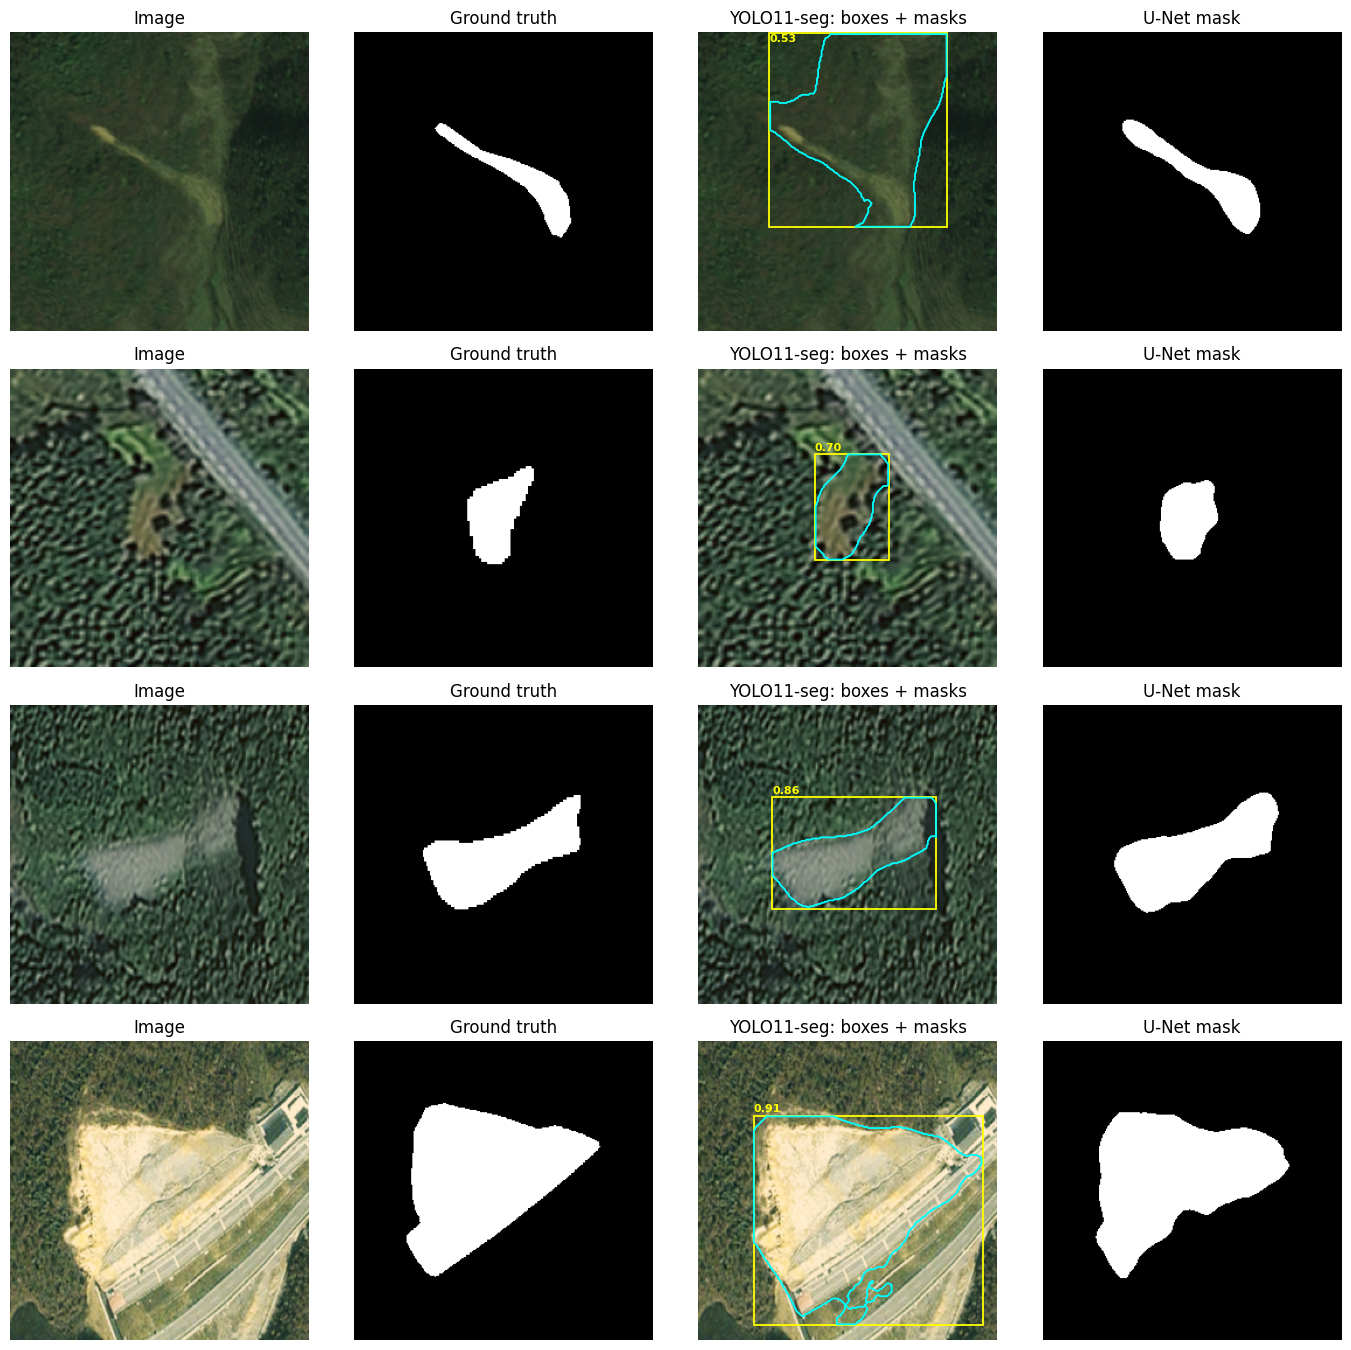

In [ ]:
names_t, cache_t, conf = yolo_cache
Pt, Tt, thr_u = unet_probs
gts = [t == 1 for t in Tt]
sel = [i for i, g in enumerate(gts) if g.sum() >= 1500][:4] or list(range(4))

fig, ax = plt.subplots(len(sel), 4, figsize=(14, 3.4 * len(sel)))
for r, i in enumerate(sel):
    img = np.array(Image.open(f'{ROOT}/images/test/{names_t[i]}.png'))
    ax[r, 0].imshow(img); ax[r, 0].set_title("Image")
    ax[r, 1].imshow(gts[i], cmap='gray'); ax[r, 1].set_title("Ground truth")
    ax[r, 2].imshow(img)
    for poly, sc, bx in zip(cache_t[i]['polys'], cache_t[i]['scores'], cache_t[i]['boxes']):
        if sc < conf: continue
        ax[r, 2].add_patch(plt.Rectangle((bx[0], bx[1]), bx[2] - bx[0], bx[3] - bx[1], fill=False, edgecolor='yellow', linewidth=1.3))
        p = np.vstack([poly, poly[:1]]); ax[r, 2].plot(p[:, 0], p[:, 1], color='cyan', linewidth=1.3)
        ax[r, 2].text(bx[0], max(bx[1] - 3, 8), f"{sc:.2f}", color='yellow', fontsize=8, fontweight='bold')
    ax[r, 2].set_title("YOLO11-seg: boxes + masks")
    ax[r, 3].imshow(Pt[i].astype(np.float32) > thr_u, cmap='gray'); ax[r, 3].set_title("U-Net mask")
    for a in ax[r]: a.axis('off')
plt.tight_layout(); plt.savefig(f'{OUT}/phase8_yolo_vs_unet.png', dpi=150); plt.show()